## Ćwiczenie 6 – Rozszerzenie 1: Unsharp Masking & High-Boost Filtering

### 1. Podbudowa teoretyczna

#### Czym jest Unsharp Masking (Wyostrzanie nieostrością)?
**Unsharp Masking** to klasyczna technika wyostrzania obrazów, wywodząca się z tradycyjnej fotografii ciemniowej, gdzie fizycznie używano rozmytej (nieostrej) kliszy jako maski do odjęcia niskich częstotliwości od oryginalnego zdjęcia. 

W cyfrowej analizie obrazów medycznych algorytm ten opisuje proste równanie:
1. **Wyznaczenie maski wyostrzającej (high-pass detail):**
   $$g_{\text{mask}}(x,y) = f(x,y) - \bar{f}(x,y)$$
   gdzie $f(x,y)$ to obraz oryginalny, a $\bar{f}(x,y)$ to jego wersja wygładzona (rozmyta, zazwyczaj filtrem Gaussa).

2. **Dodanie maski do obrazu oryginalnego ze współczynnikiem wzmocnienia $k$:**
   $$g(x,y) = f(x,y) + k \cdot g_{\text{mask}}(x,y)$$

#### Klasyfikacja ze względu na parametr $k$:
* **$k = 1$:** Klasyczne *Unsharp Masking*.
* **$k > 1$:** Tzw. **High-Boost Filtering** – silne podbicie wysokich częstotliwości, stosowane przy bardzo słabym kontraście krawędziowym.
* **$k < 1$:** Łagodne wyostrzanie.

#### Zastosowanie w Diagnostyce Medycznej
W radiologii (np. **mammografia**, **RTG klatki piersiowej**) wyostrzanie nieostrością pozwala wyciągnąć drobne, ostre struktury (takie jak **mikrozwapnienia** czy drobne rysy złamań w kościach) bez całkowitego usuwania informacji o łagodnych przejściach tonalnych narządów.

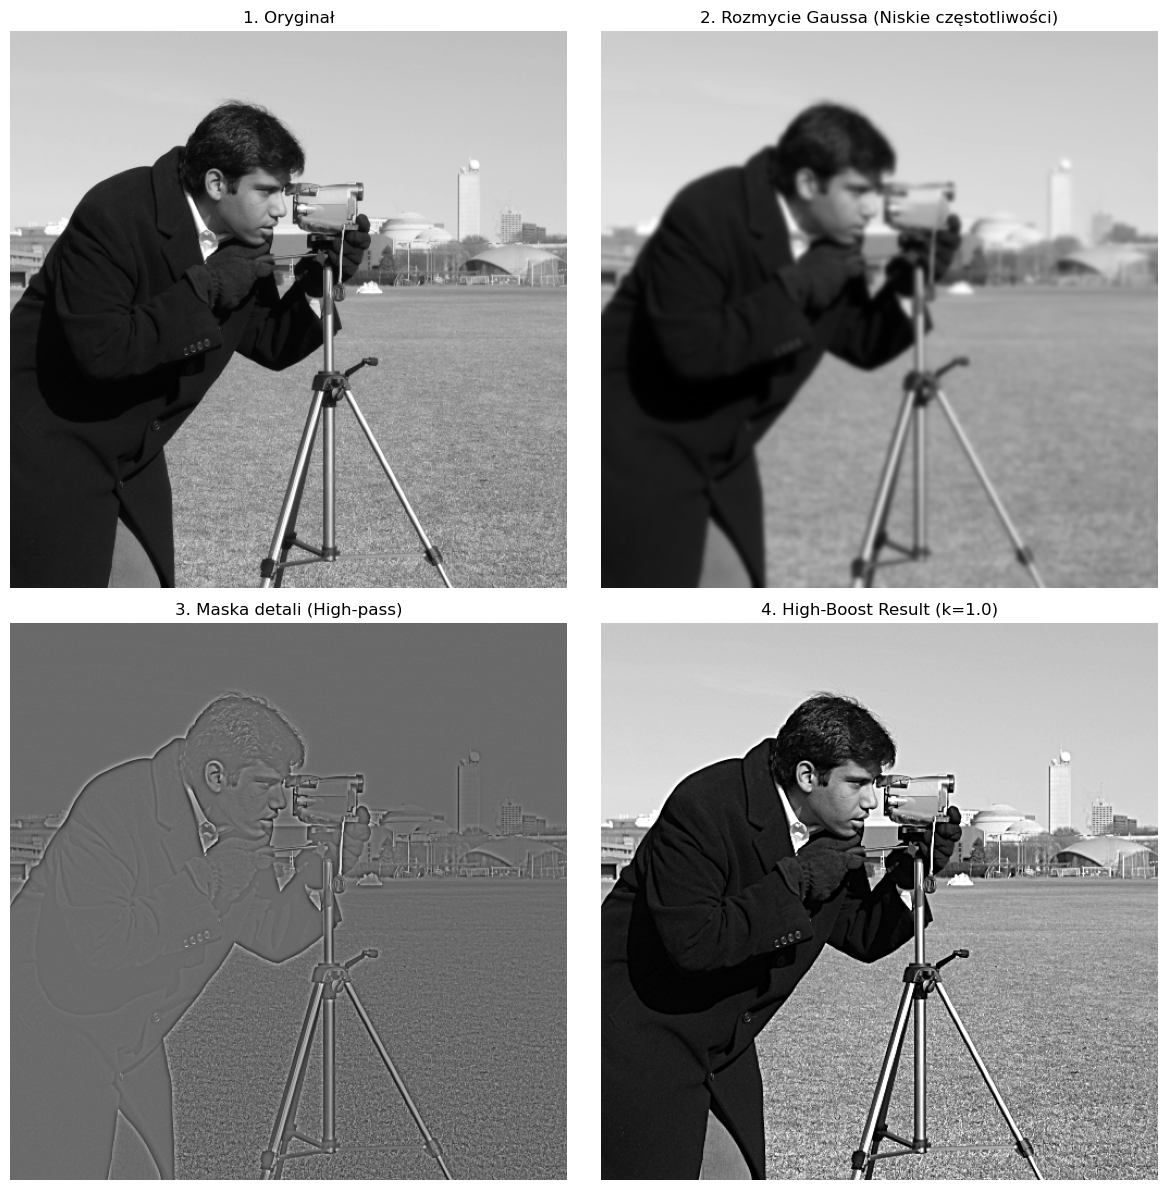

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, util

# 1. Wczytanie obrazu referencyjnego (Fantom Sheppa-Logana / Camera)
image = data.camera() / 255.0

# 2. Ręczna implementacja krok po kroku
sigma = 2.0
k = 1.0  # Współczynnik High-Boost

blurred_img = filters.gaussian(image, sigma=sigma)
mask_detail = image - blurred_img
high_boost_img = image + k * mask_detail

# Przycięcie zak zakresu [0, 1] dla poprawnej wizualizacji
high_boost_img = np.clip(high_boost_img, 0, 1)

# 3. Użycie gotowej funkcji ze skimage.filters.unsharp_mask
skimage_unsharp = filters.unsharp_mask(image, radius=2, amount=1.5)

# Vizualizacja
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes[0, 0].imshow(image, cmap='gray'); axes[0, 0].set_title('1. Oryginał')
axes[0, 1].imshow(blurred_img, cmap='gray'); axes[0, 1].set_title('2. Rozmycie Gaussa (Niskie częstotliwości)')
axes[1, 0].imshow(mask_detail, cmap='gray'); axes[1, 0].set_title('3. Maska detali (High-pass)')
axes[1, 1].imshow(high_boost_img, cmap='gray'); axes[1, 1].set_title(f'4. High-Boost Result (k={k})')

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

### Pytanie analityczne dla studenta:
*Co dzieje się z szumem tła, gdy zwiększamy wartość parametru $k$ (np. $k = 3.0$)? Jak w praktyce klinicznej dobrać kompromis między wyostrzaniem mikrostruktur a wzmacnianiem szumu?*